## Configuration

Set the path to your queryset file here:

In [18]:
# ========================================
# QUERYSET FILE PATH
# ========================================
# Set this to the path of the queryset file you want to visualize
# Examples:
#   - "../data/lubm_queries/raw/59410580"
#   - "../data/wikidata_queries/raw/<filename>"
#   - "../data/dbpedia100k_star_queries/raw/<filename>"
#   - "../data/swdf_path_queries/raw/<filename>"

QUERYSET_FILE = "/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/swdf_path_queries/raw/60037112?private_link=81b137c60854d11ee270"
QUERYSET_FILE = '/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/swdf_star_queries/raw/59320652'

print(f"📍 Queryset file configured: {QUERYSET_FILE}")

📍 Queryset file configured: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/swdf_star_queries/raw/59320652


# Query Graph Visualization

This notebook visualizes random query graphs from FICE queryset files. It can load any queryset file (star or path queries) and display the query structure as directed graphs.

## Features
- Load queries from JSON files
- Automatically detect query type (star vs path)
- Adaptive layout selection (circular for star, spring for path)
- URI simplification for readability
- Random sampling with configurable sample size
- Statistics and cardinality distribution

## Available Querysets

**Star Queries:**
- `data/lubm_queries/raw/`
- `data/wikidata_queries/raw/`
- `data/dbpedia100k_star_queries/raw/`
- `data/swdf_star_queries/raw/`
- `data/fb237_v4_star_queries/raw/`
- `data/wn18rr_v4_star_queries/raw/`

**Path Queries:**
- `data/lubm_path_queries/raw/`
- `data/wikidata_path_queries/raw/`
- `data/dbpedia100k_path_queries/raw/`
- `data/swdf_path_queries/raw/`
- `data/fb237_v4_path_queries/raw/`
- `data/wn18rr_v4_path_queries/raw/`

## 1. Setup and Imports

In [19]:
import json
import random
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Publication-quality configuration
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans', 'Helvetica']
plt.rcParams['font.size'] = 28
plt.rcParams['axes.linewidth'] = 3.0
plt.rcParams['axes.labelsize'] = 28
plt.rcParams['axes.titlesize'] = 28
plt.rcParams['xtick.labelsize'] = 22
plt.rcParams['ytick.labelsize'] = 22
plt.rcParams['legend.fontsize'] = 22
plt.rcParams['figure.dpi'] = 150  # Higher DPI for better quality
plt.rcParams['savefig.dpi'] = 300  # Publication quality
plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['pdf.fonttype'] = 42  # TrueType fonts for PDF (required by publishers)
plt.rcParams['ps.fonttype'] = 42

RANDOM_SEED = None
random.seed(RANDOM_SEED)

# Professional color scheme (colorblind-friendly)
COLOR_VARIABLE = '#4A90E2'  # Professional blue
COLOR_ENTITY = '#50C878'     # Emerald green
EDGE_COLOR = '#2C3E50'       # Dark slate
EDGE_LABEL_COLOR = '#E74C3C' # Coral red

print("✓ Imports successful - Publication-quality settings enabled")

✓ Imports successful - Publication-quality settings enabled


## 2. Helper Functions

### URI Simplification

Convert URIs to readable labels: `<http://example.org/123>` → `e:123` for entities, `r:123` for relations

In [20]:
def simplify_uri(uri, is_predicate=False):
    """
    Simplify URI for display.
    
    Args:
        uri: URI string like "<http://example.org/123>"
        is_predicate: If True, use 'r:' prefix, otherwise 'e:'
    
    Returns:
        Simplified string like "e:123" or "r:123"
    """
    if uri.startswith('?'):
        # Variable - return as is
        return uri
    
    # Remove angle brackets
    uri = uri.strip('<>')
    
    # Extract the last part after the last '/'
    if '/' in uri:
        parts = uri.split('/')
        identifier = parts[-1]
    else:
        identifier = uri
    
    # Use appropriate prefix
    prefix = 'r' if is_predicate else 'e'
    return f"{prefix}:{identifier}"

### Query Type Detection

Detect if a query is a **star query** (multiple triples sharing a common subject) or a **path query** (chain pattern).

In [21]:
def detect_query_type(query):
    """
    Detect if a query is a star or path query.
    
    Args:
        query: Query dict with 'triples' field
    
    Returns:
        'star' or 'path'
    """
    triples = query['triples']
    
    if len(triples) <= 1:
        return 'star'
    
    # Count occurrences of each subject
    subjects = [t[0] for t in triples]
    subject_counts = Counter(subjects)
    
    # If one subject dominates (appears in >50% of triples), it's likely a star query
    max_count = max(subject_counts.values())
    if max_count / len(triples) > 0.5:
        return 'star'
    
    return 'path'

### Graph Conversion

Convert query triple patterns to NetworkX directed graph.

In [22]:
def query_to_networkx(query):
    """
    Convert query dict to NetworkX DiGraph.
    
    Args:
        query: Query dict with 'triples' field
    
    Returns:
        G: NetworkX DiGraph
        node_map: Dict mapping original names to node IDs
    """
    G = nx.DiGraph()
    node_map = {}
    node_id_counter = 0
    
    # Build graph from triples
    for triple in query['triples']:
        subj, pred, obj = triple[0], triple[1], triple[2]
        
        # Map subject
        if subj not in node_map:
            node_map[subj] = node_id_counter
            node_id_counter += 1
        
        # Map object
        if obj not in node_map:
            node_map[obj] = node_id_counter
            node_id_counter += 1
        
        # Add edge with predicate as attribute
        G.add_edge(
            node_map[subj], 
            node_map[obj], 
            label=simplify_uri(pred, is_predicate=True),
            original_label=pred
        )
    
    # Add node labels: variables keep their names, entities get numeric indices
    inv_map = {v: k for k, v in node_map.items()}
    entity_counter = 1
    for node_id, original_name in inv_map.items():
        is_variable = original_name.startswith('?')
        if is_variable:
            # Keep variable names as-is
            G.nodes[node_id]['label'] = original_name
        else:
            # Use numeric indices for entities
            G.nodes[node_id]['label'] = str(entity_counter)
            entity_counter += 1
        G.nodes[node_id]['original_label'] = original_name
        G.nodes[node_id]['simplified_label'] = simplify_uri(original_name)
        G.nodes[node_id]['is_variable'] = is_variable
    
    return G, node_map

## 3. Visualization Function

Adaptive visualization that automatically selects layout based on query type.

In [23]:
def visualize_query(query, ax=None, title_prefix="", show_legend=False, publication_mode=True):
    """
    Visualize a single query graph with adaptive layout (publication quality).
    
    Args:
        query: Query dict with 'triples' and 'y' fields
        ax: Matplotlib axis (creates new figure if None)
        title_prefix: Prefix for the title
        show_legend: Whether to show legend
        publication_mode: If True, use publication-quality settings
    
    Returns:
        fig, ax
    """
    # Convert to NetworkX graph
    G, node_map = query_to_networkx(query)
    
    # Detect query type and select layout
    query_type = detect_query_type(query)
    
    if query_type == 'star':
        # Circular layout for star queries
        pos = nx.circular_layout(G, scale=1.0)
    else:
        # Kamada-Kawai layout for better path visualization
        try:
            pos = nx.kamada_kawai_layout(G, scale=1.5)
        except:
            pos = nx.spring_layout(G, k=1.5, iterations=100, seed=RANDOM_SEED)
    
    # Create figure if needed
    if ax is None:
        fig, ax = plt.subplots(figsize=(16, 14))
    else:
        fig = ax.figure
    
    # Prepare node colors with better styling
    num_nodes = G.number_of_nodes()
    num_edges = G.number_of_edges()
    
    node_colors = []
    for n in G.nodes():
        if G.nodes[n]['is_variable']:
            node_colors.append(COLOR_VARIABLE)
        else:
            node_colors.append(COLOR_ENTITY)
    
    # Publication-quality sizing
    if publication_mode:
        node_size = max(3000, 6000 - num_nodes * 100)
        font_size = max(24, 32 - num_nodes * 0.4)
        edge_font_size = max(22, 28 - num_edges * 0.2)
        edge_width = 6.0
        arrow_size = 80
    else:
        node_size = max(1500, 3500 - num_nodes * 60)
        font_size = max(20, 28 - num_nodes * 0.4)
        edge_font_size = max(18, 24 - num_edges * 0.2)
        edge_width = 4.5
        arrow_size = 60
    
    # Draw edges FIRST so arrows appear behind nodes
    nx.draw_networkx_edges(
        G, pos,
        edge_color=EDGE_COLOR,
        arrows=True,
        arrowsize=arrow_size,
        arrowstyle='->',
        width=edge_width,
        alpha=0.85,
        connectionstyle='arc3,rad=0.1',  # Slight curve for better visibility
        min_target_margin=20,  # Stop arrows before reaching node center
        ax=ax
    )
    
    # Draw nodes with professional styling (AFTER edges so they're on top)
    nx.draw_networkx_nodes(
        G, pos,
        node_color=node_colors,
        node_size=node_size,
        alpha=0.95,
        edgecolors='#2C3E50',
        linewidths=4.0,
        ax=ax
    )
    
    # Draw node labels with better contrast
    node_labels = {n: G.nodes[n]['label'] for n in G.nodes()}
    nx.draw_networkx_labels(
        G, pos,
        labels=node_labels,
        font_size=font_size,
        font_weight='bold',
        font_color='white',
        ax=ax
    )
    
    # Draw edge labels (predicates) - adaptive threshold
    if num_edges <= 20:
        edge_labels = nx.get_edge_attributes(G, 'label')
        nx.draw_networkx_edge_labels(
            G, pos,
            edge_labels=edge_labels,
            font_size=edge_font_size,
            font_color=EDGE_LABEL_COLOR,
            font_weight='bold',
            bbox=dict(alpha=0),  # Fully transparent background
            ax=ax
        )
    
    # No title or cardinality display for clean publication figures
    
    # Professional legend
    if show_legend:
        from matplotlib.patches import Patch
        legend_elements = [
            Patch(facecolor=COLOR_VARIABLE, edgecolor='#2C3E50', 
                  linewidth=3.5, label='Variable'),
            Patch(facecolor=COLOR_ENTITY, edgecolor='#2C3E50', 
                  linewidth=3.5, label='Entity')
        ]
        ax.legend(handles=legend_elements, loc='upper right', 
                 fontsize=16, framealpha=0.95, edgecolor='#2C3E50')
    
    ax.axis('off')
    plt.tight_layout()
    
    return fig, ax

## 4. Query Loading and Statistics

In [ ]:
def load_queryset(file_path, show_stats=True):
    """
    Load queries from a JSON file and optionally display statistics.
    
    Args:
        file_path: Path to query JSON file (string or Path)
        show_stats: Whether to display statistics and plots
    
    Returns:
        List of query dicts
    """
    file_path = Path(file_path)
    
    if not file_path.exists():
        raise FileNotFoundError(f"Query file not found: {file_path}")
    
    # Load JSON
    with open(file_path, 'r') as f:
        queries = json.load(f)
    
    print(f"📂 Loaded queryset: {file_path.name}")
    print(f"📊 Total queries: {len(queries)}")
    
    if show_stats and len(queries) > 0:
        # Cardinality statistics
        cardinalities = [q.get('y', 0) for q in queries]
        print(f"\n🔢 Cardinality Statistics:")
        print(f"   Min: {min(cardinalities)}")
        print(f"   Max: {max(cardinalities)}")
        print(f"   Mean: {np.mean(cardinalities):.2f}")
        print(f"   Median: {np.median(cardinalities):.2f}")
        
        # Triple count statistics
        triple_counts = [len(q.get('triples', [])) for q in queries]
        print(f"\n📐 Triple Count Statistics:")
        print(f"   Min: {min(triple_counts)}")
        print(f"   Max: {max(triple_counts)}")
        print(f"   Mean: {np.mean(triple_counts):.2f}")
        
        # Query type distribution
        query_types = [detect_query_type(q) for q in queries]
        type_counts = Counter(query_types)
        print(f"\n🔍 Query Type Distribution:")
        for qtype, count in type_counts.items():
            print(f"   {qtype.capitalize()}: {count} ({count/len(queries)*100:.1f}%)")
        
        # Plot cardinality distribution
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
        
        # Histogram of cardinalities (log scale)
        ax1.hist(cardinalities, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
        ax1.set_xlabel('Cardinality (log scale)', fontsize=11)
        ax1.set_ylabel('Frequency', fontsize=11)
        ax1.set_title('Cardinality Distribution', fontsize=12, fontweight='bold')
        ax1.set_yscale('log')
        ax1.grid(False)
        
        # Histogram of triple counts
        ax2.hist(triple_counts, bins=range(min(triple_counts), max(triple_counts)+2), 
                 edgecolor='black', alpha=0.7, color='coral')
        ax2.set_xlabel('Number of Triples', fontsize=11)
        ax2.set_ylabel('Frequency', fontsize=11)
        ax2.set_title('Triple Count Distribution', fontsize=12, fontweight='bold')
        ax2.grid(False)
        
        plt.tight_layout()
        plt.show()
    
    return queries

## 5. Random Query Visualization

Visualize multiple random queries in a grid layout.

In [25]:
def visualize_random_queries(queries, n=5, seed=None, figsize_per_plot=(14, 12)):
    """
    Visualize n random queries from a queryset.
    
    Args:
        queries: List of query dicts
        n: Number of queries to sample and visualize
        seed: Random seed for reproducibility
        figsize_per_plot: Size of each subplot
    
    Returns:
        fig, axes
    """
    if seed is not None:
        random.seed(seed)
    
    # Sample queries
    n = min(n, len(queries))
    sampled_queries = random.sample(queries, n)
    
    # Calculate grid dimensions
    ncols = min(3, n)  # Max 3 columns
    nrows = (n + ncols - 1) // ncols  # Ceiling division
    
    # Create figure
    figsize = (figsize_per_plot[0] * ncols, figsize_per_plot[1] * nrows)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    
    # Handle case of single plot
    if n == 1:
        axes = np.array([axes])
    axes = axes.flatten() if n > 1 else axes
    
    # Visualize each query
    for idx, (query, ax) in enumerate(zip(sampled_queries, axes)):
        visualize_query(
            query, 
            ax=ax, 
            title_prefix=f"#{idx+1} | ",
            show_legend=(idx == 0)  # Show legend only on first plot
        )
    
    # Hide unused subplots
    for idx in range(n, len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    
    return fig, axes

## 6. Example Usage

### 6.1 Load a Queryset

Choose a queryset file from the available datasets. You can browse files in the data directories or use the helper below.

In [26]:
# Helper function to list available querysets
def list_available_querysets(base_path="../data"):
    """List all available queryset files."""
    base = Path(base_path)
    
    print("📁 Available Querysets:\n")
    
    # Find all directories ending with _queries
    query_dirs = sorted([d for d in base.iterdir() if d.is_dir() and 'queries' in d.name])
    
    for query_dir in query_dirs:
        raw_dir = query_dir / "raw"
        if raw_dir.exists():
            files = sorted([f for f in raw_dir.iterdir() if f.is_file()])
            if files:
                print(f"  {query_dir.name}/raw/")
                for f in files[:3]:  # Show first 3 files
                    print(f"    - {f.name}")
                if len(files) > 3:
                    print(f"    ... and {len(files) - 3} more files")
                print()

list_available_querysets()

📁 Available Querysets:

  dbpedia100k_path_queries/raw/
    - 59898644?private_link=d6411dc19831edc2f780

  dbpedia100k_star_queries/raw/
    - 59687708?private_link=1e23a3388a4b6b6161d1

  fb237_v4_ind_path_queries/raw/
    - 59900708?private_link=103743702bc11e9b4672

  fb237_v4_ind_star_queries/raw/
    - 59731859?private_link=953281688dbdb230c09d

  fb237_v4_path_queries/raw/
    - 59900678?private_link=69c356b2701ace402cf9

  fb237_v4_star_queries/raw/
    - 59651327?private_link=780ccfbe4856b223d7b5

  lubm_path_queries/raw/
    - 60037037?private_link=8e4493e070acfd065b77

  lubm_queries/raw/
    - 59410580

  swdf_path_queries/raw/
    - .DS_Store
    - 60037112?private_link=81b137c60854d11ee270

  swdf_star_queries/raw/
    - 59320652

  wikidata_path_queries/raw/
    - 60037220?private_link=435c4febc01f57ca3b6d

  wikidata_queries/raw/
    - 59320583

  wn18rr_v4_ind_path_queries/raw/
    - 59898623?private_link=87c951797ea81f7c43f0

  wn18rr_v4_ind_star_queries/raw/
    - 59

📂 Loaded queryset: 59320652
📊 Total queries: 116645

🔢 Cardinality Statistics:
   Min: 1
   Max: 1048576
   Mean: 318.33
   Median: 2.00

📐 Triple Count Statistics:
   Min: 2
   Max: 8
   Mean: 4.54

🔍 Query Type Distribution:
   Star: 116645 (100.0%)


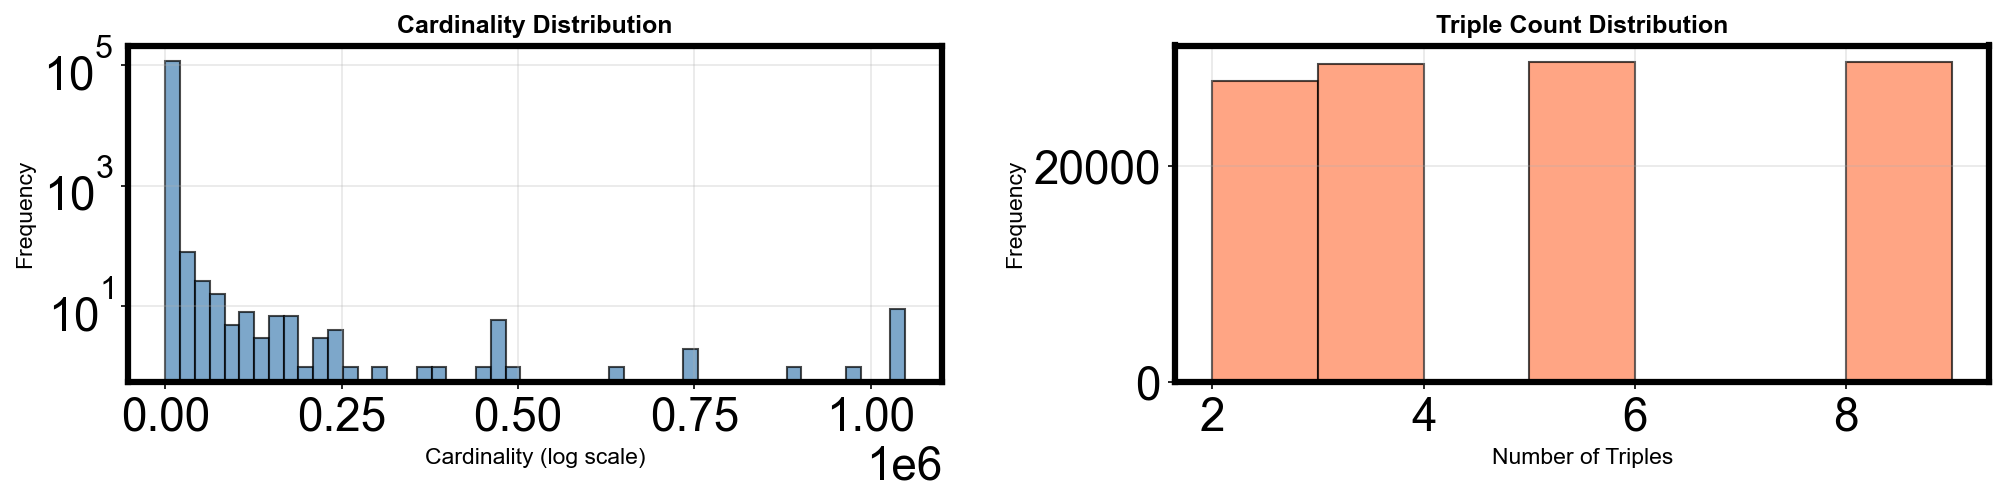

In [27]:
# Load queries using the configured path
queries = load_queryset(QUERYSET_FILE, show_stats=True)

### 6.2 Visualize Random Queries

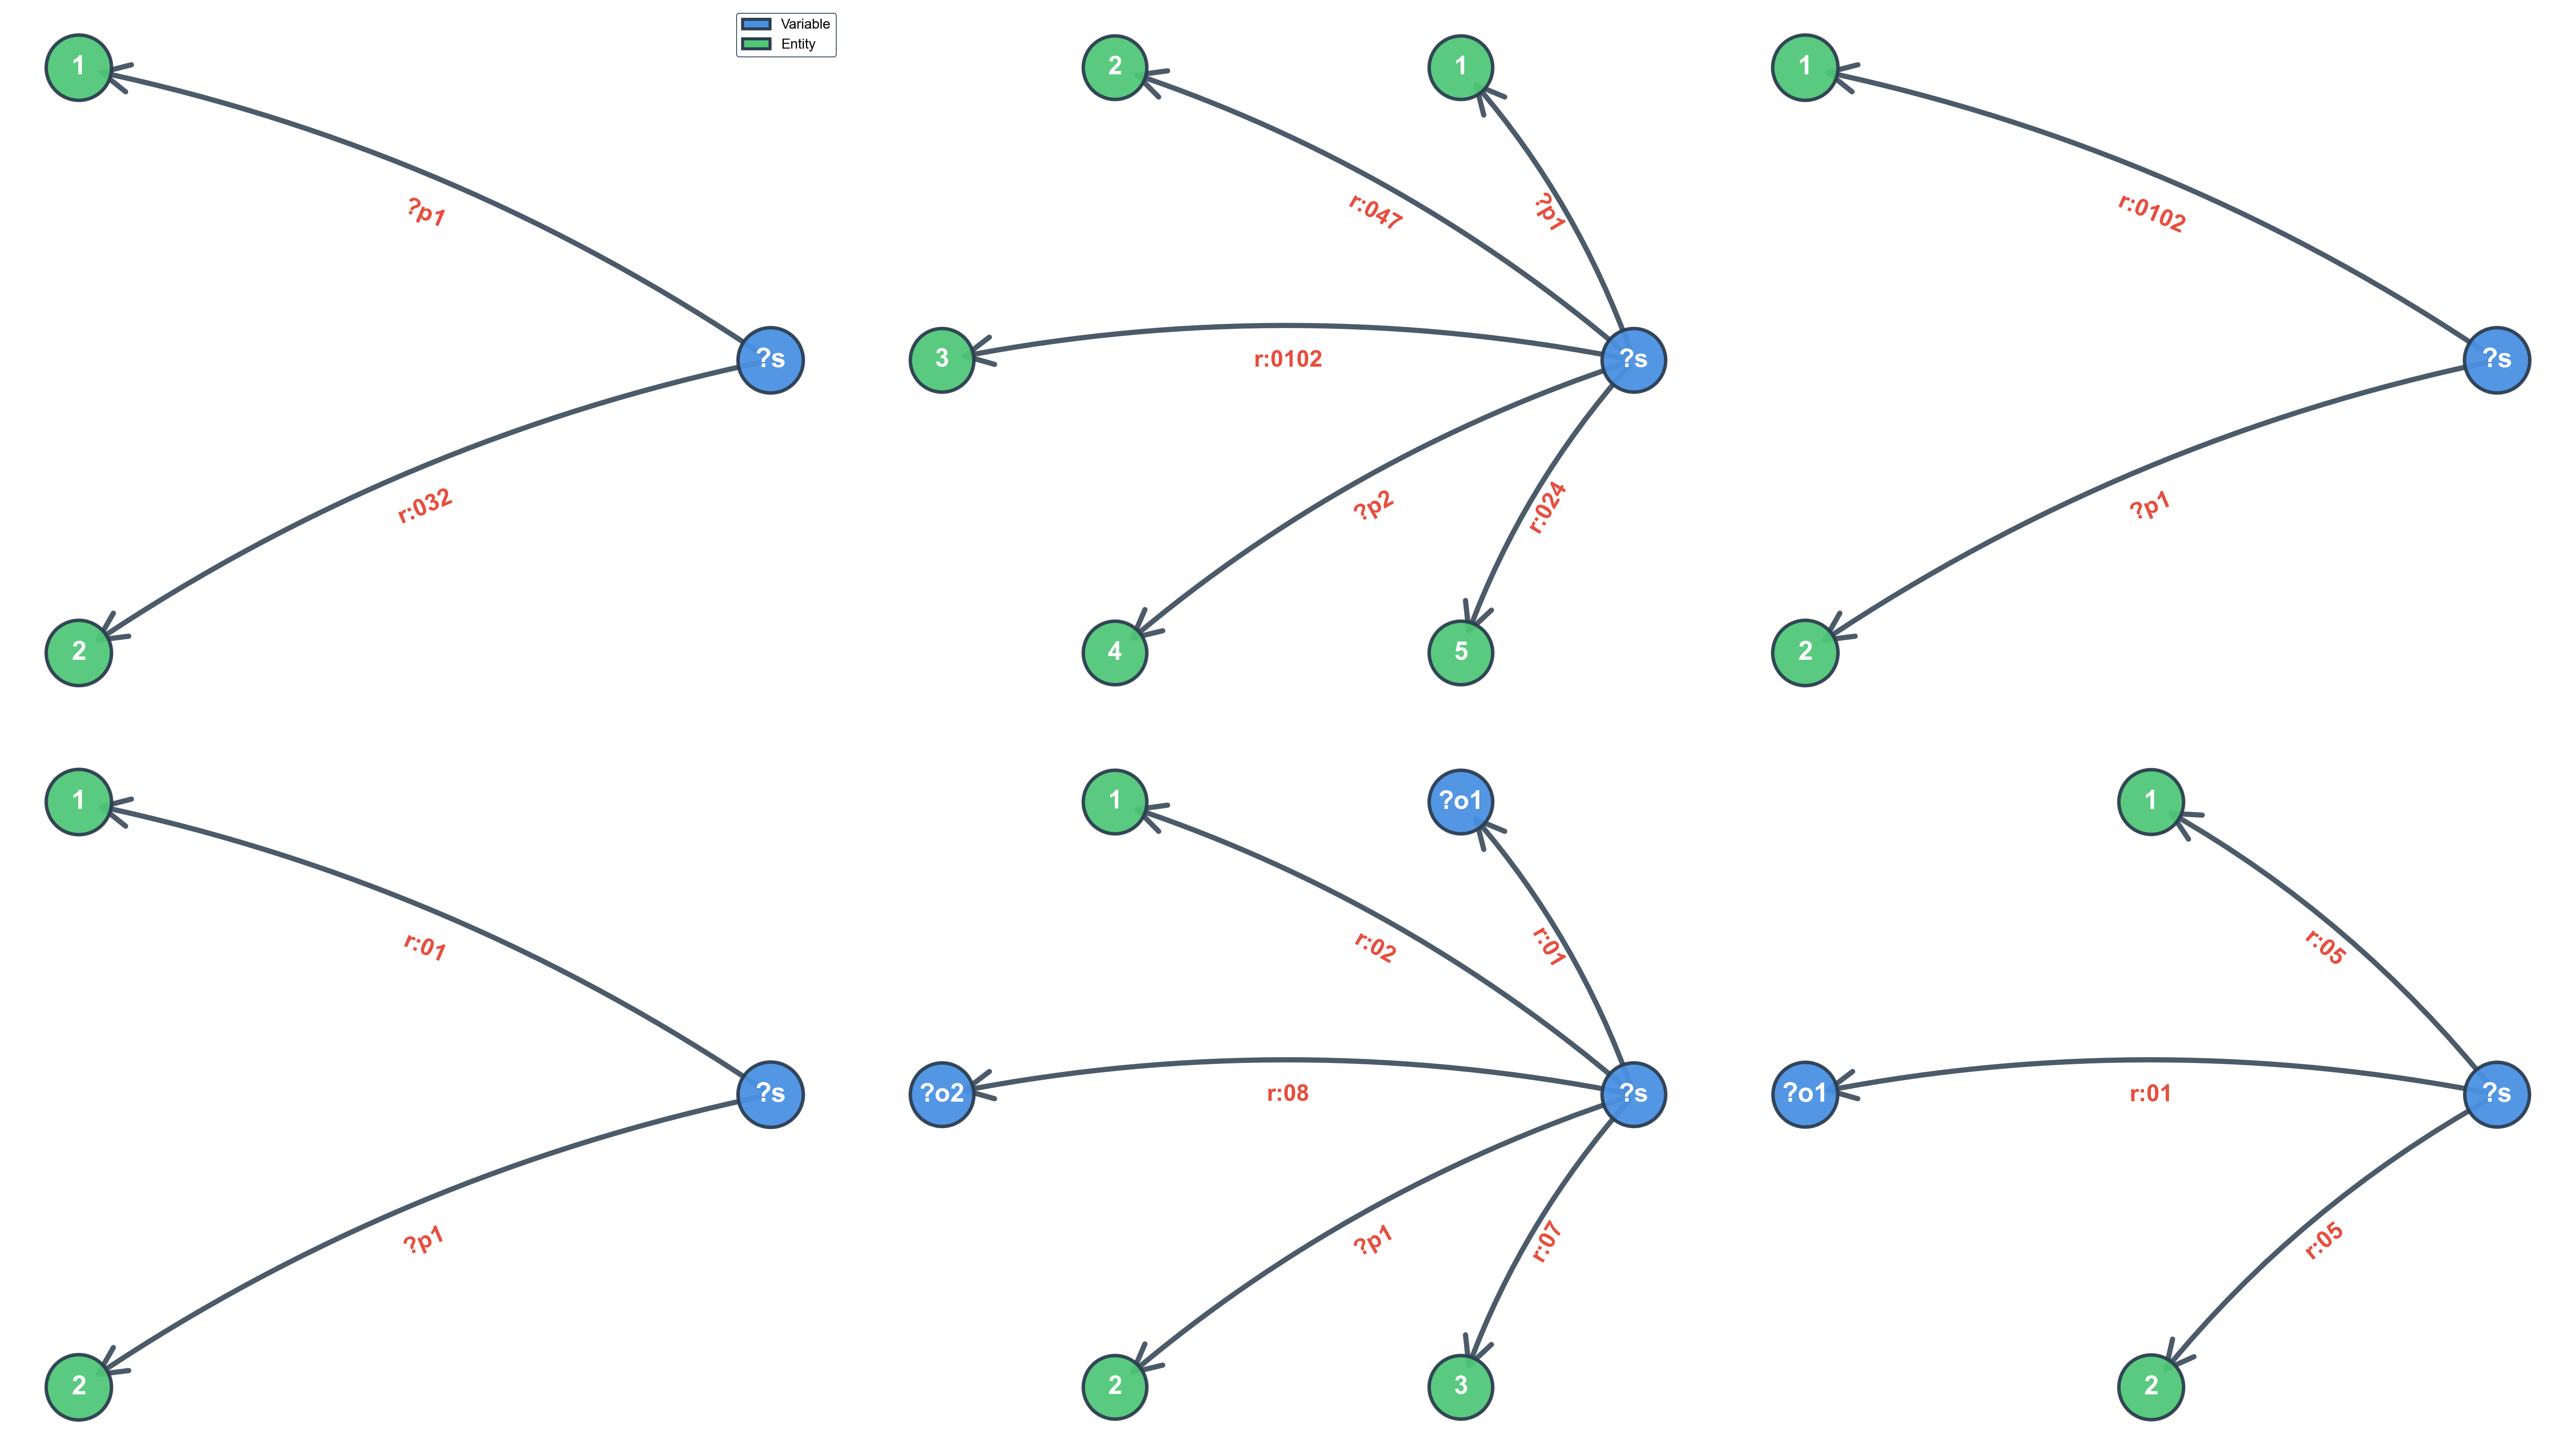

In [28]:
# Visualize 6 random queries
fig, axes = visualize_random_queries(queries, n=6, seed=RANDOM_SEED)
plt.show()

### 6.3 Visualize a Single Query

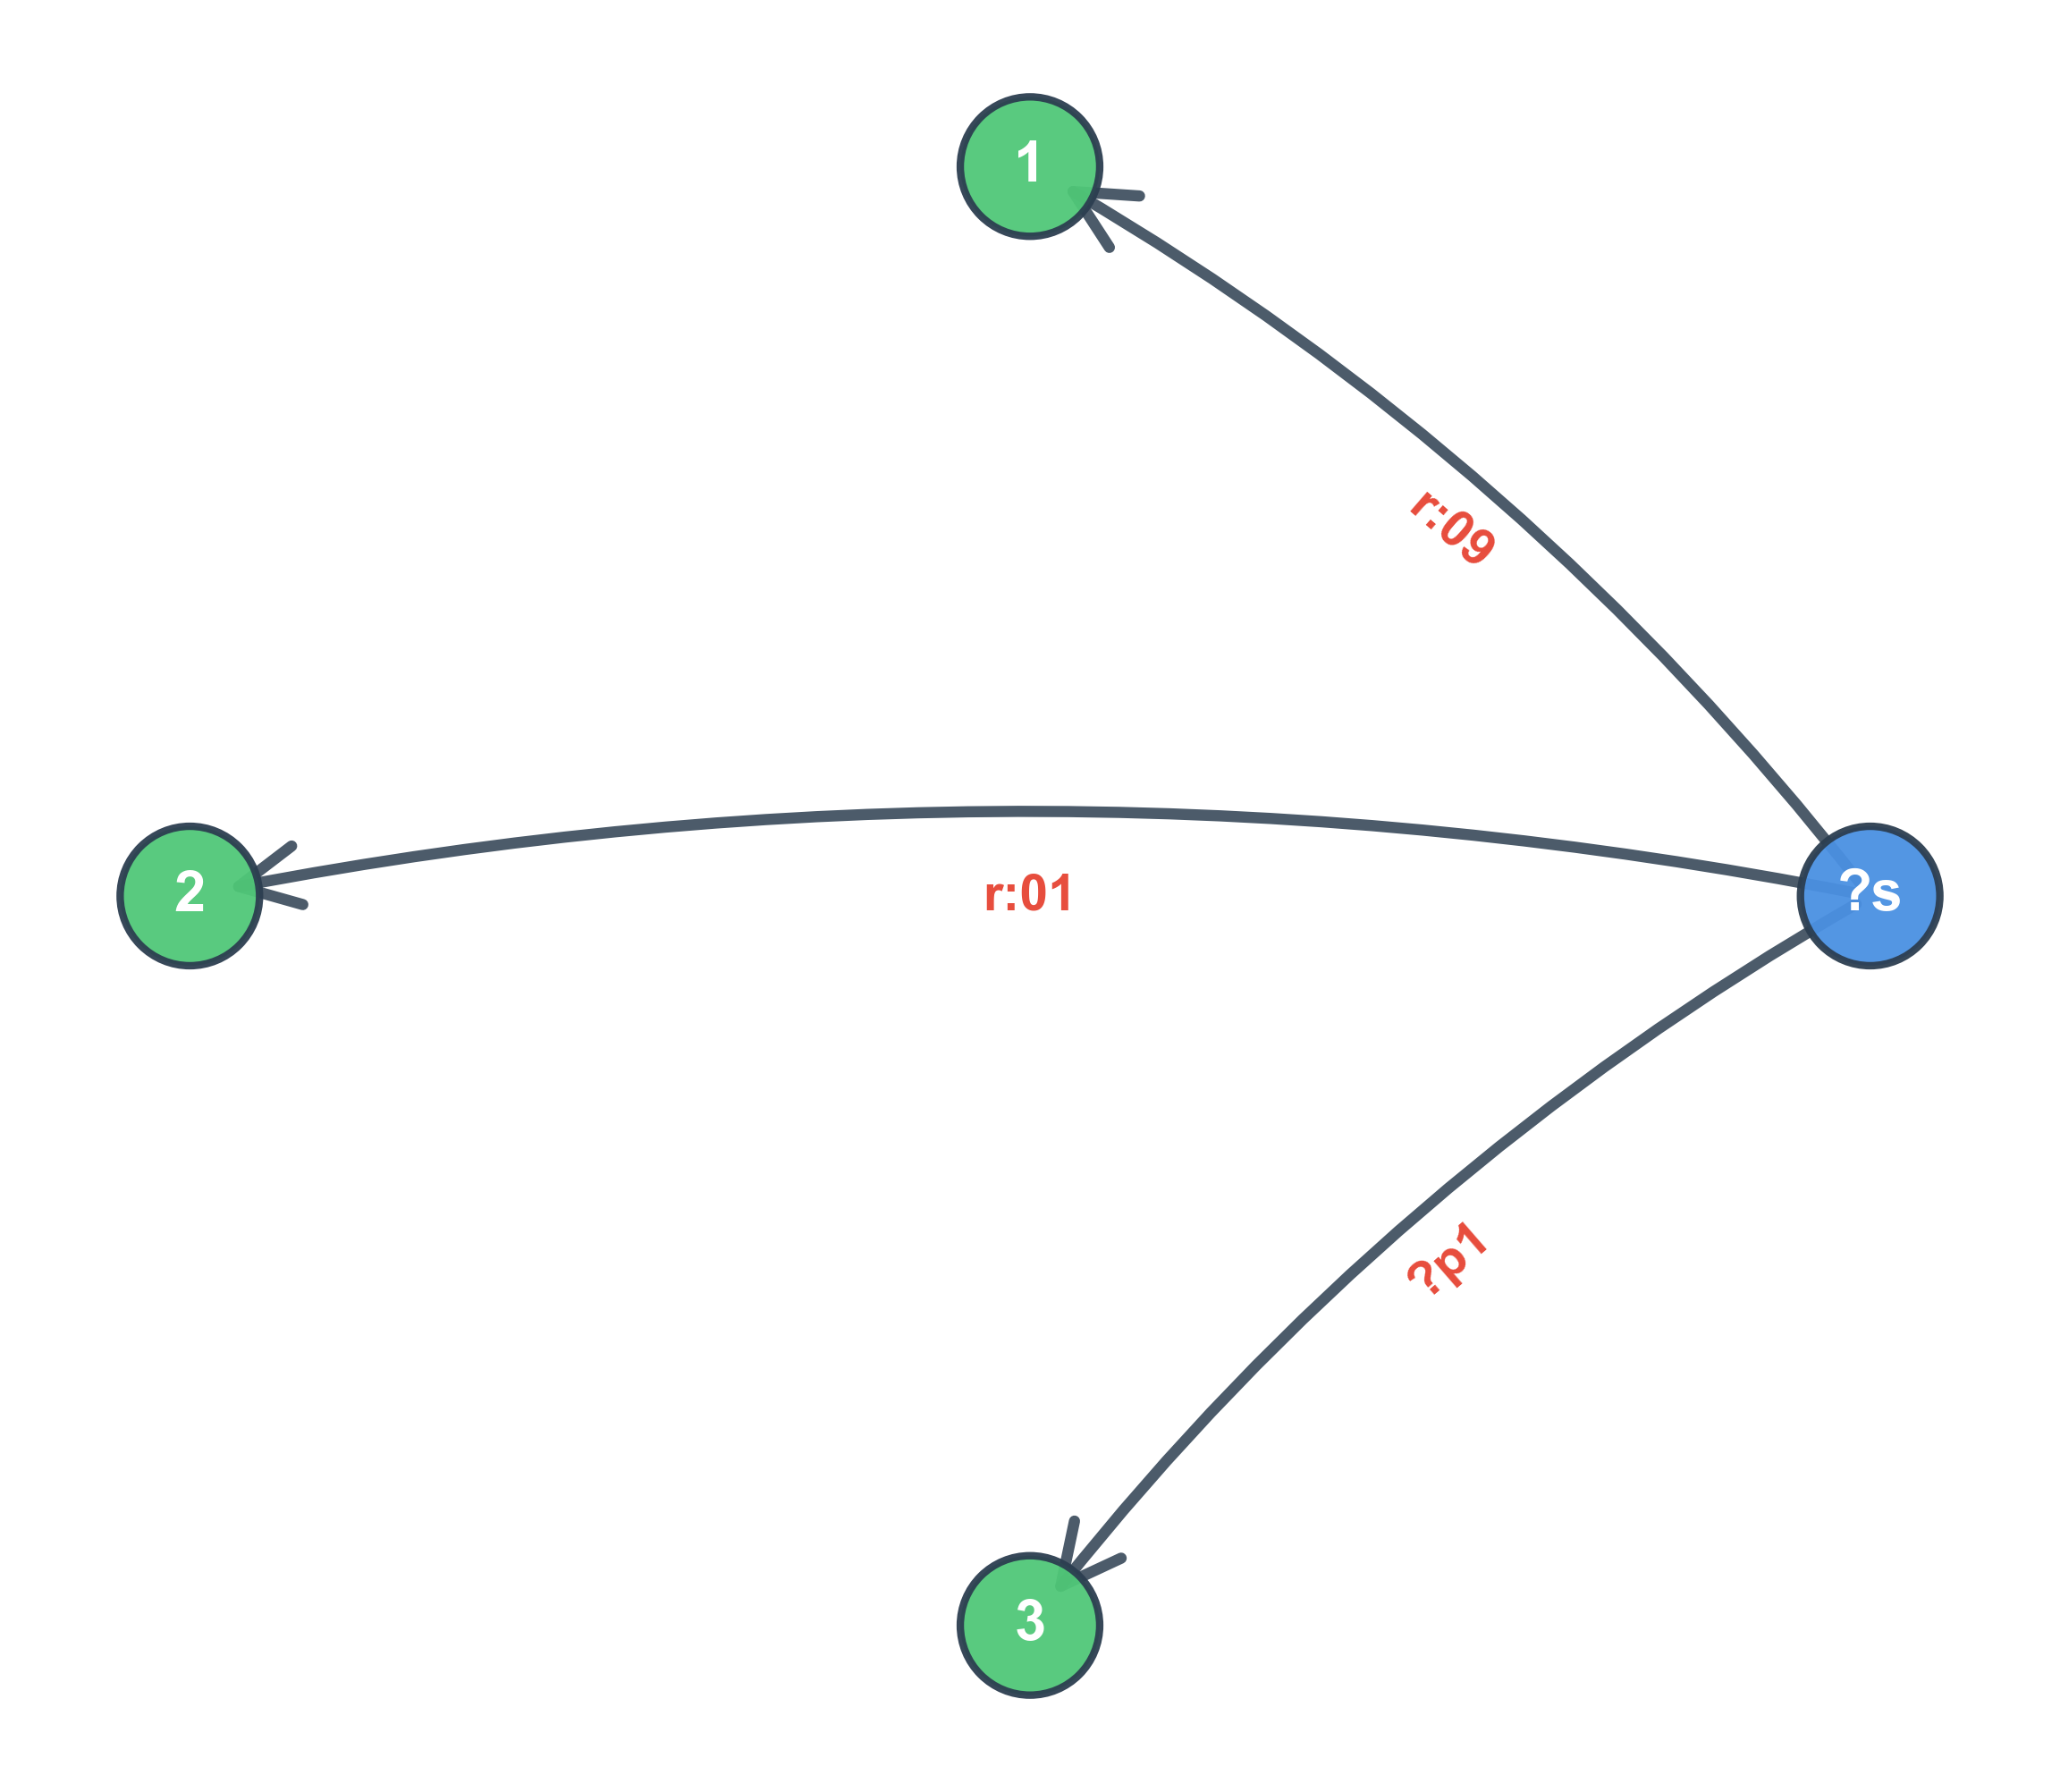


Query Details:
Query Index: 47890
Cardinality: 1
Number of triples: 3

Triple patterns:
  1. ?s              <http://ex.org/09>                       <http://ex.org/2031>
  2. ?s              <http://ex.org/01>                       <http://ex.org/2014>
  3. ?s              ?p1                                      <http://ex.org/2007>


In [29]:
# Visualize a specific query by index
query_index = random.randint(0, len(queries) - 1)  # Change this to visualize different queries
# query_index = 8374
# query_index = 0
fig, ax = visualize_query(queries[query_index])
plt.show()
fig.savefig(f"query_{query_index}_visualization.pdf")
fig.savefig(f"query_{query_index}_visualization.jpg")

# Print query details
print(f"\nQuery Details:")
print(f"Query Index: {query_index}")
print(f"Cardinality: {queries[query_index].get('y', 'N/A')}")
print(f"Number of triples: {len(queries[query_index]['triples'])}")
print(f"\nTriple patterns:")
for i, triple in enumerate(queries[query_index]['triples'], 1):
    print(f"  {i}. {triple[0]:15} {triple[1]:40} {triple[2]:15}")

### 6.4 Filter and Visualize Queries by Cardinality

Visualize queries with specific cardinality ranges.

Found 87192 queries with cardinality between 1 and 10


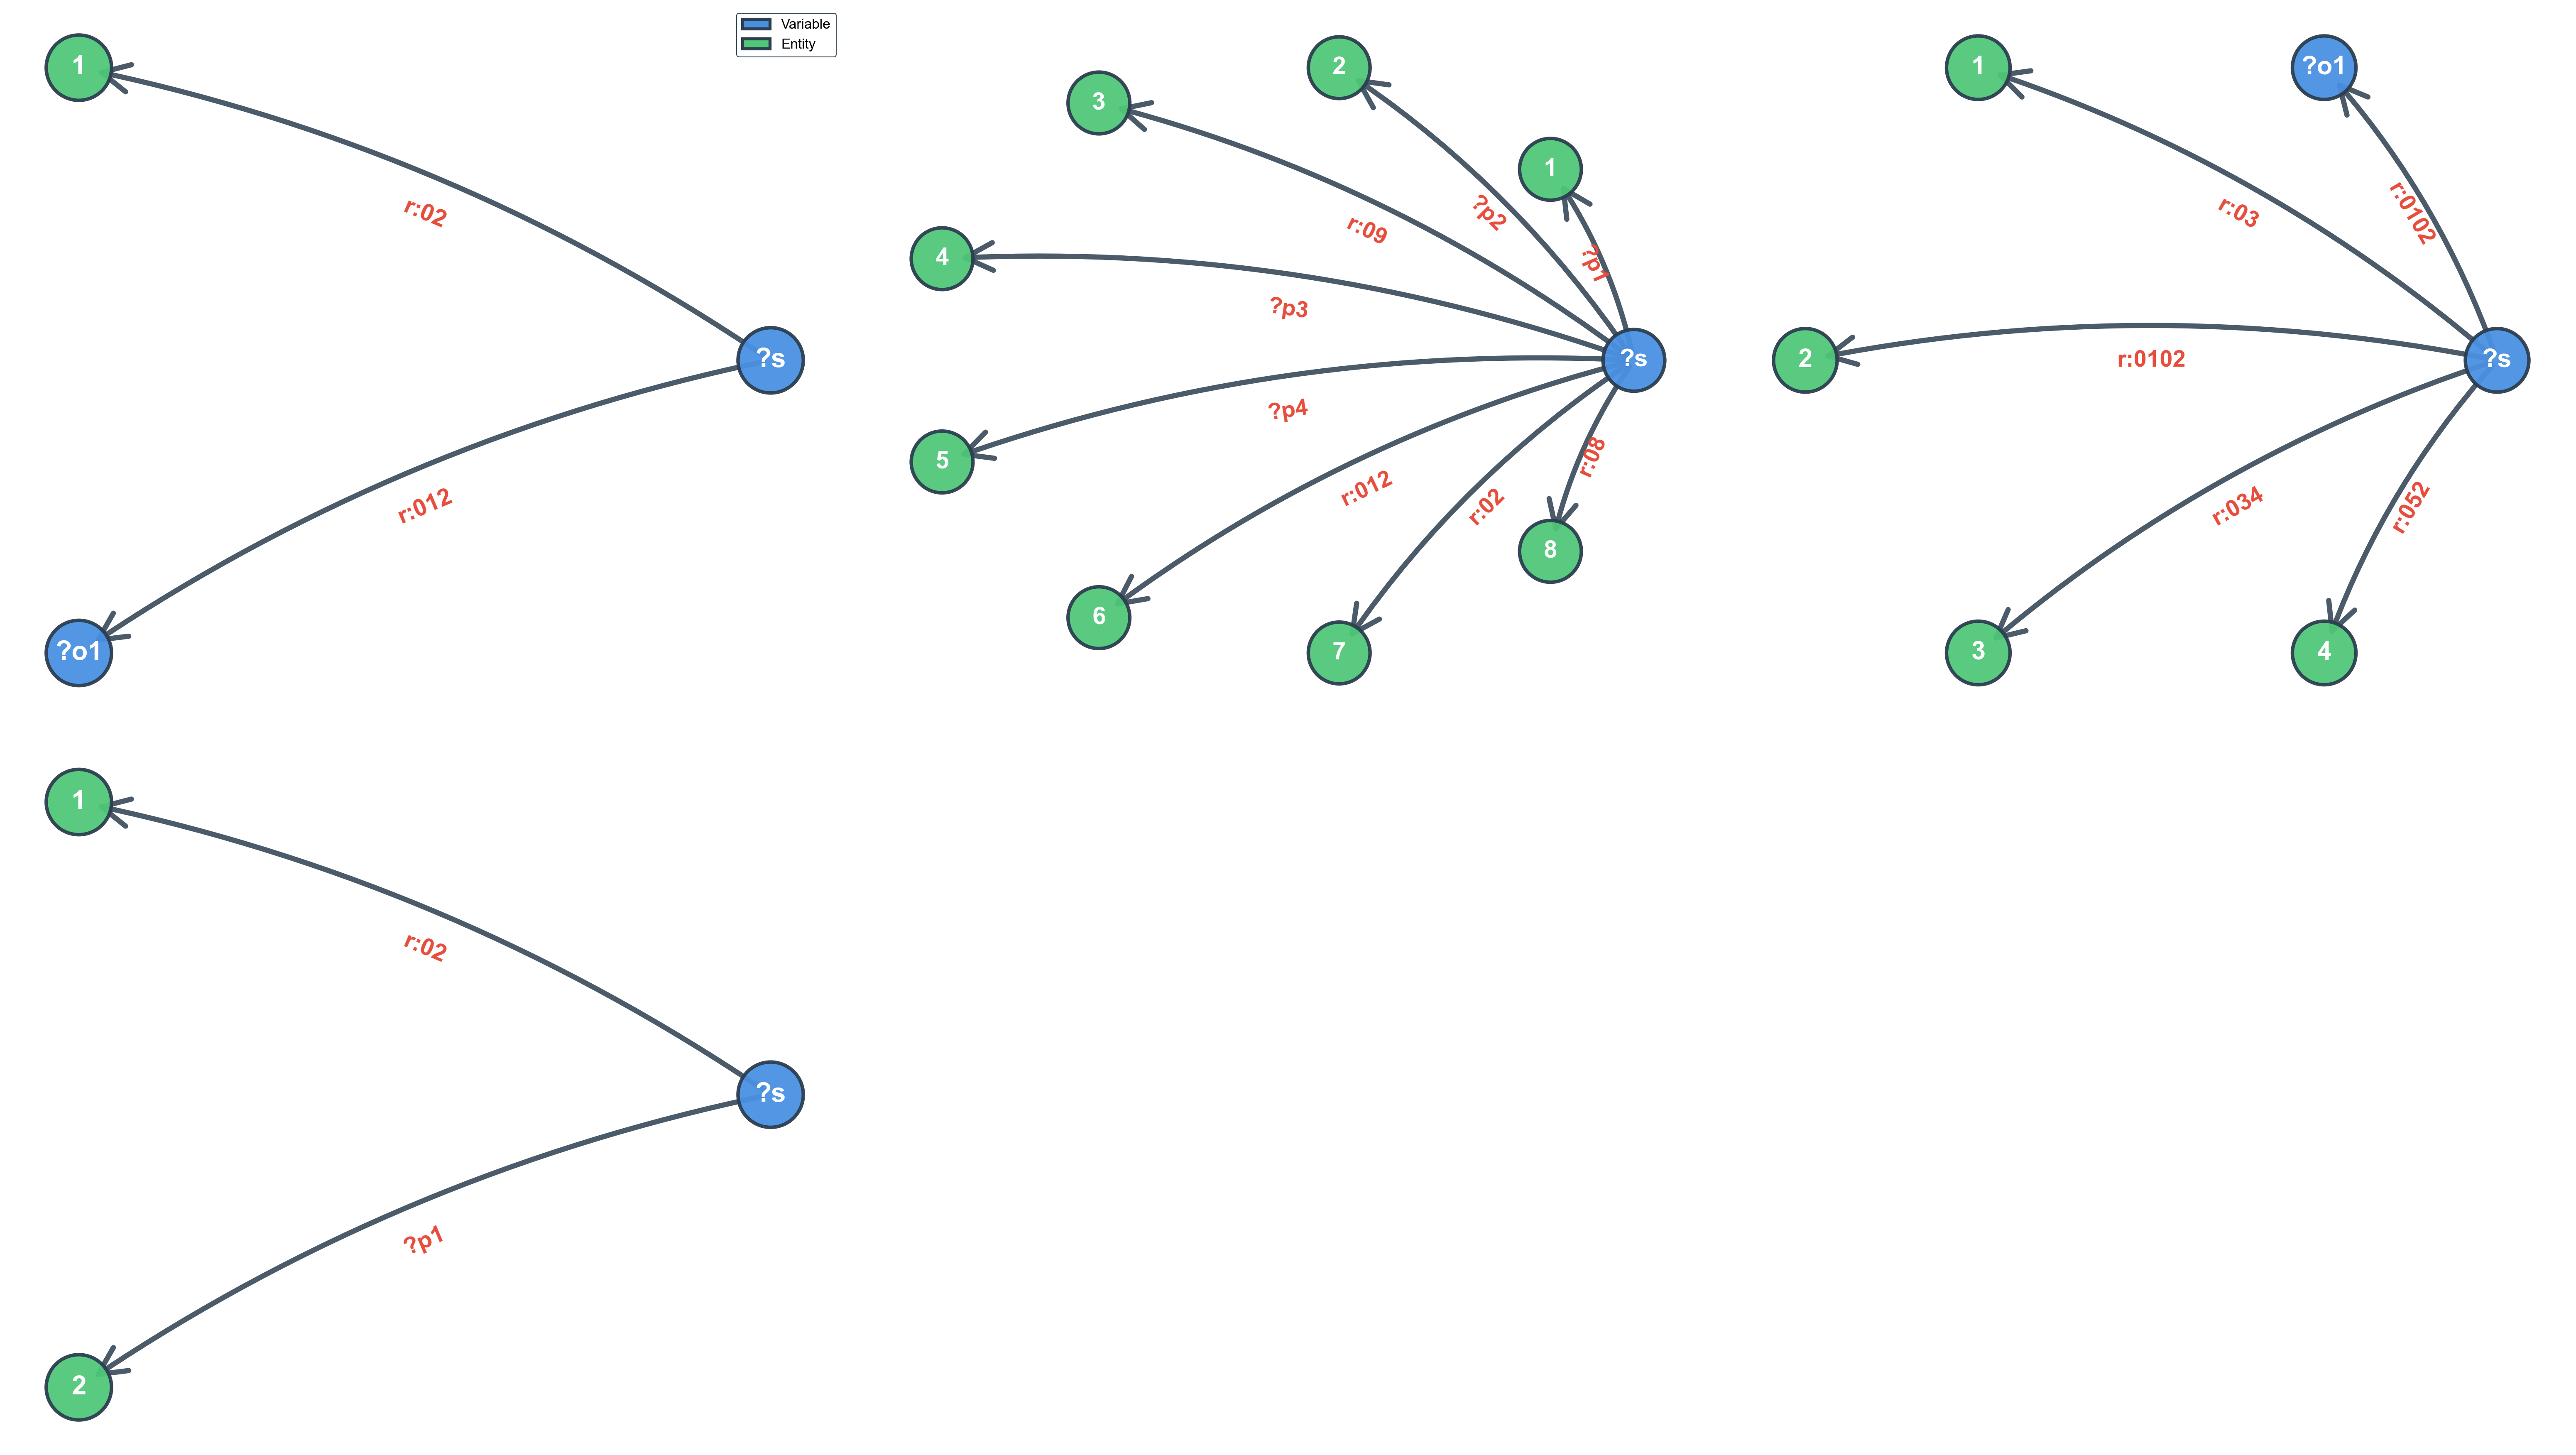

In [30]:
# Filter queries by cardinality range
min_cardinality = 1
max_cardinality = 10

filtered_queries = [
    q for q in queries 
    if min_cardinality <= q.get('y', 0) <= max_cardinality
]

print(f"Found {len(filtered_queries)} queries with cardinality between {min_cardinality} and {max_cardinality}")

# Visualize some of the filtered queries
if len(filtered_queries) > 0:
    fig, axes = visualize_random_queries(filtered_queries, n=min(4, len(filtered_queries)), seed=RANDOM_SEED)
    plt.show()
else:
    print("No queries found with specified cardinality range.")

### 6.5 Filter by Number of Triples

Visualize queries with a specific number of triple patterns.

Found 29461 queries with exactly 3 triples


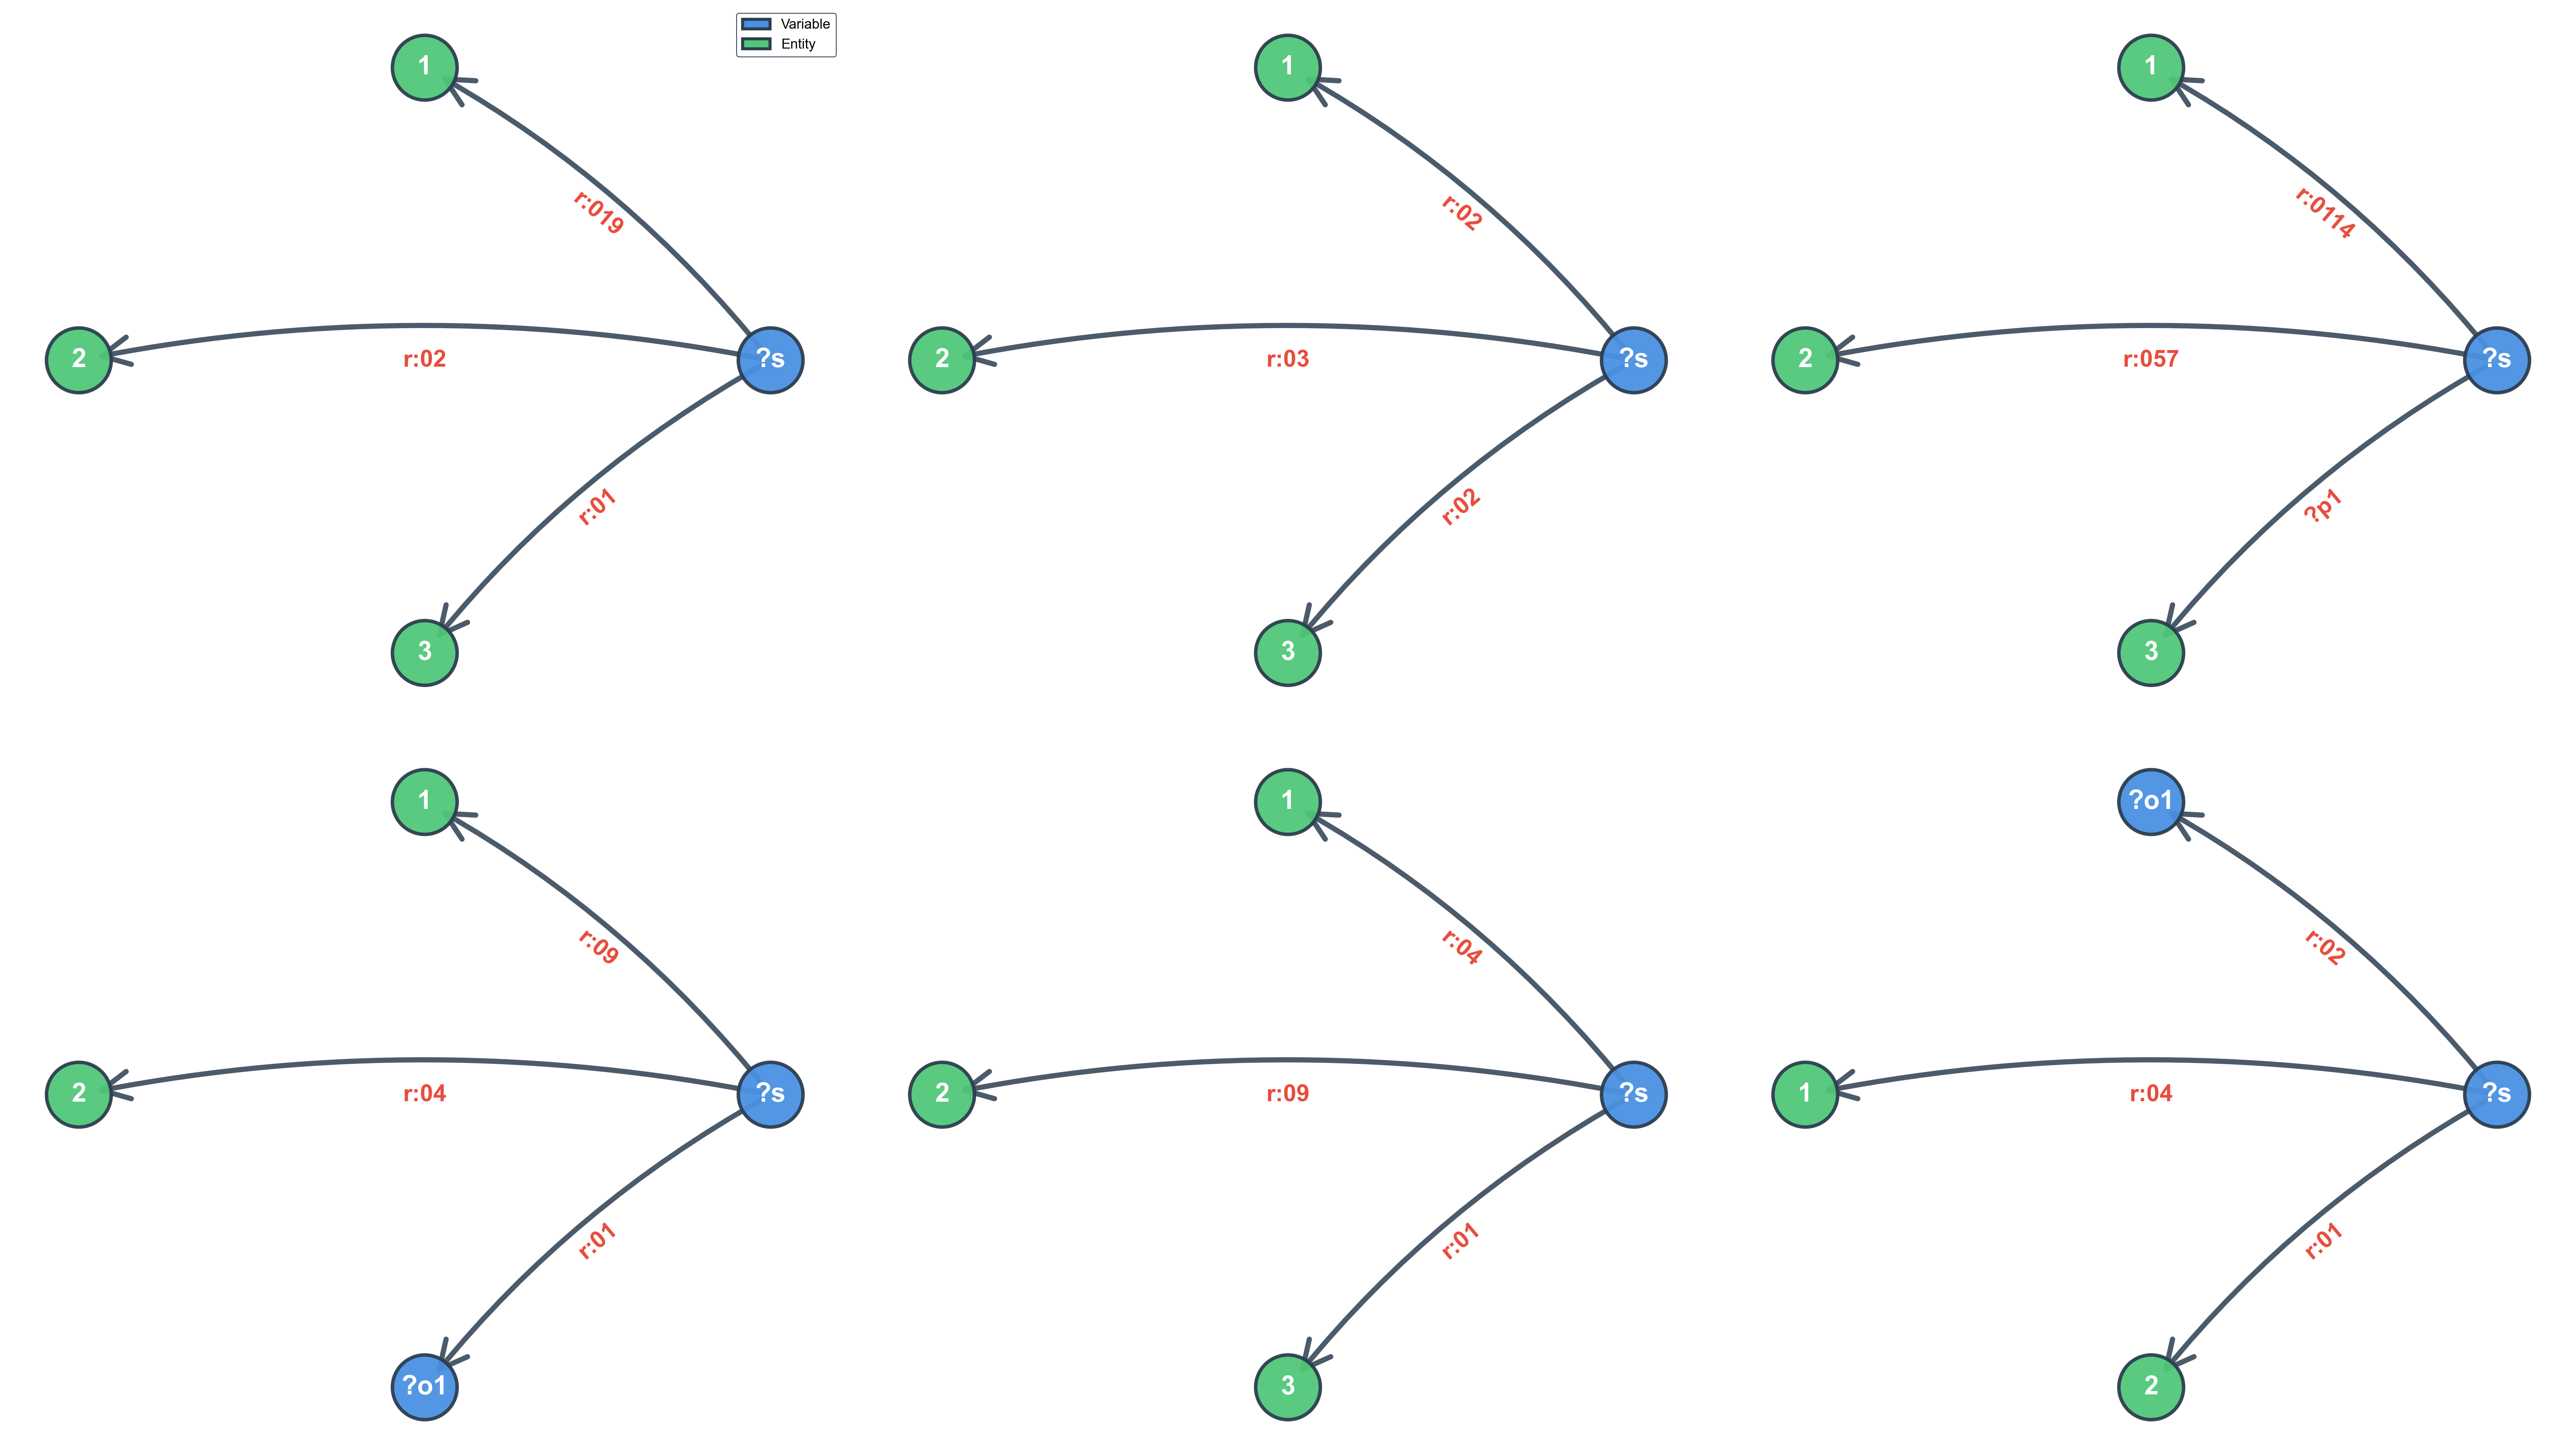

In [31]:
# Filter by number of triples
num_triples = 3  # Change this value

filtered_by_triples = [
    q for q in queries 
    if len(q.get('triples', [])) == num_triples
]

print(f"Found {len(filtered_by_triples)} queries with exactly {num_triples} triples")

if len(filtered_by_triples) > 0:
    fig, axes = visualize_random_queries(filtered_by_triples, n=min(6, len(filtered_by_triples)), seed=RANDOM_SEED)
    plt.show()
else:
    print(f"No queries found with {num_triples} triples.")

### 6.6 Compare Star vs Path Queries

Visualize examples of each query type side by side.

Star queries: 116645
Path queries: 0


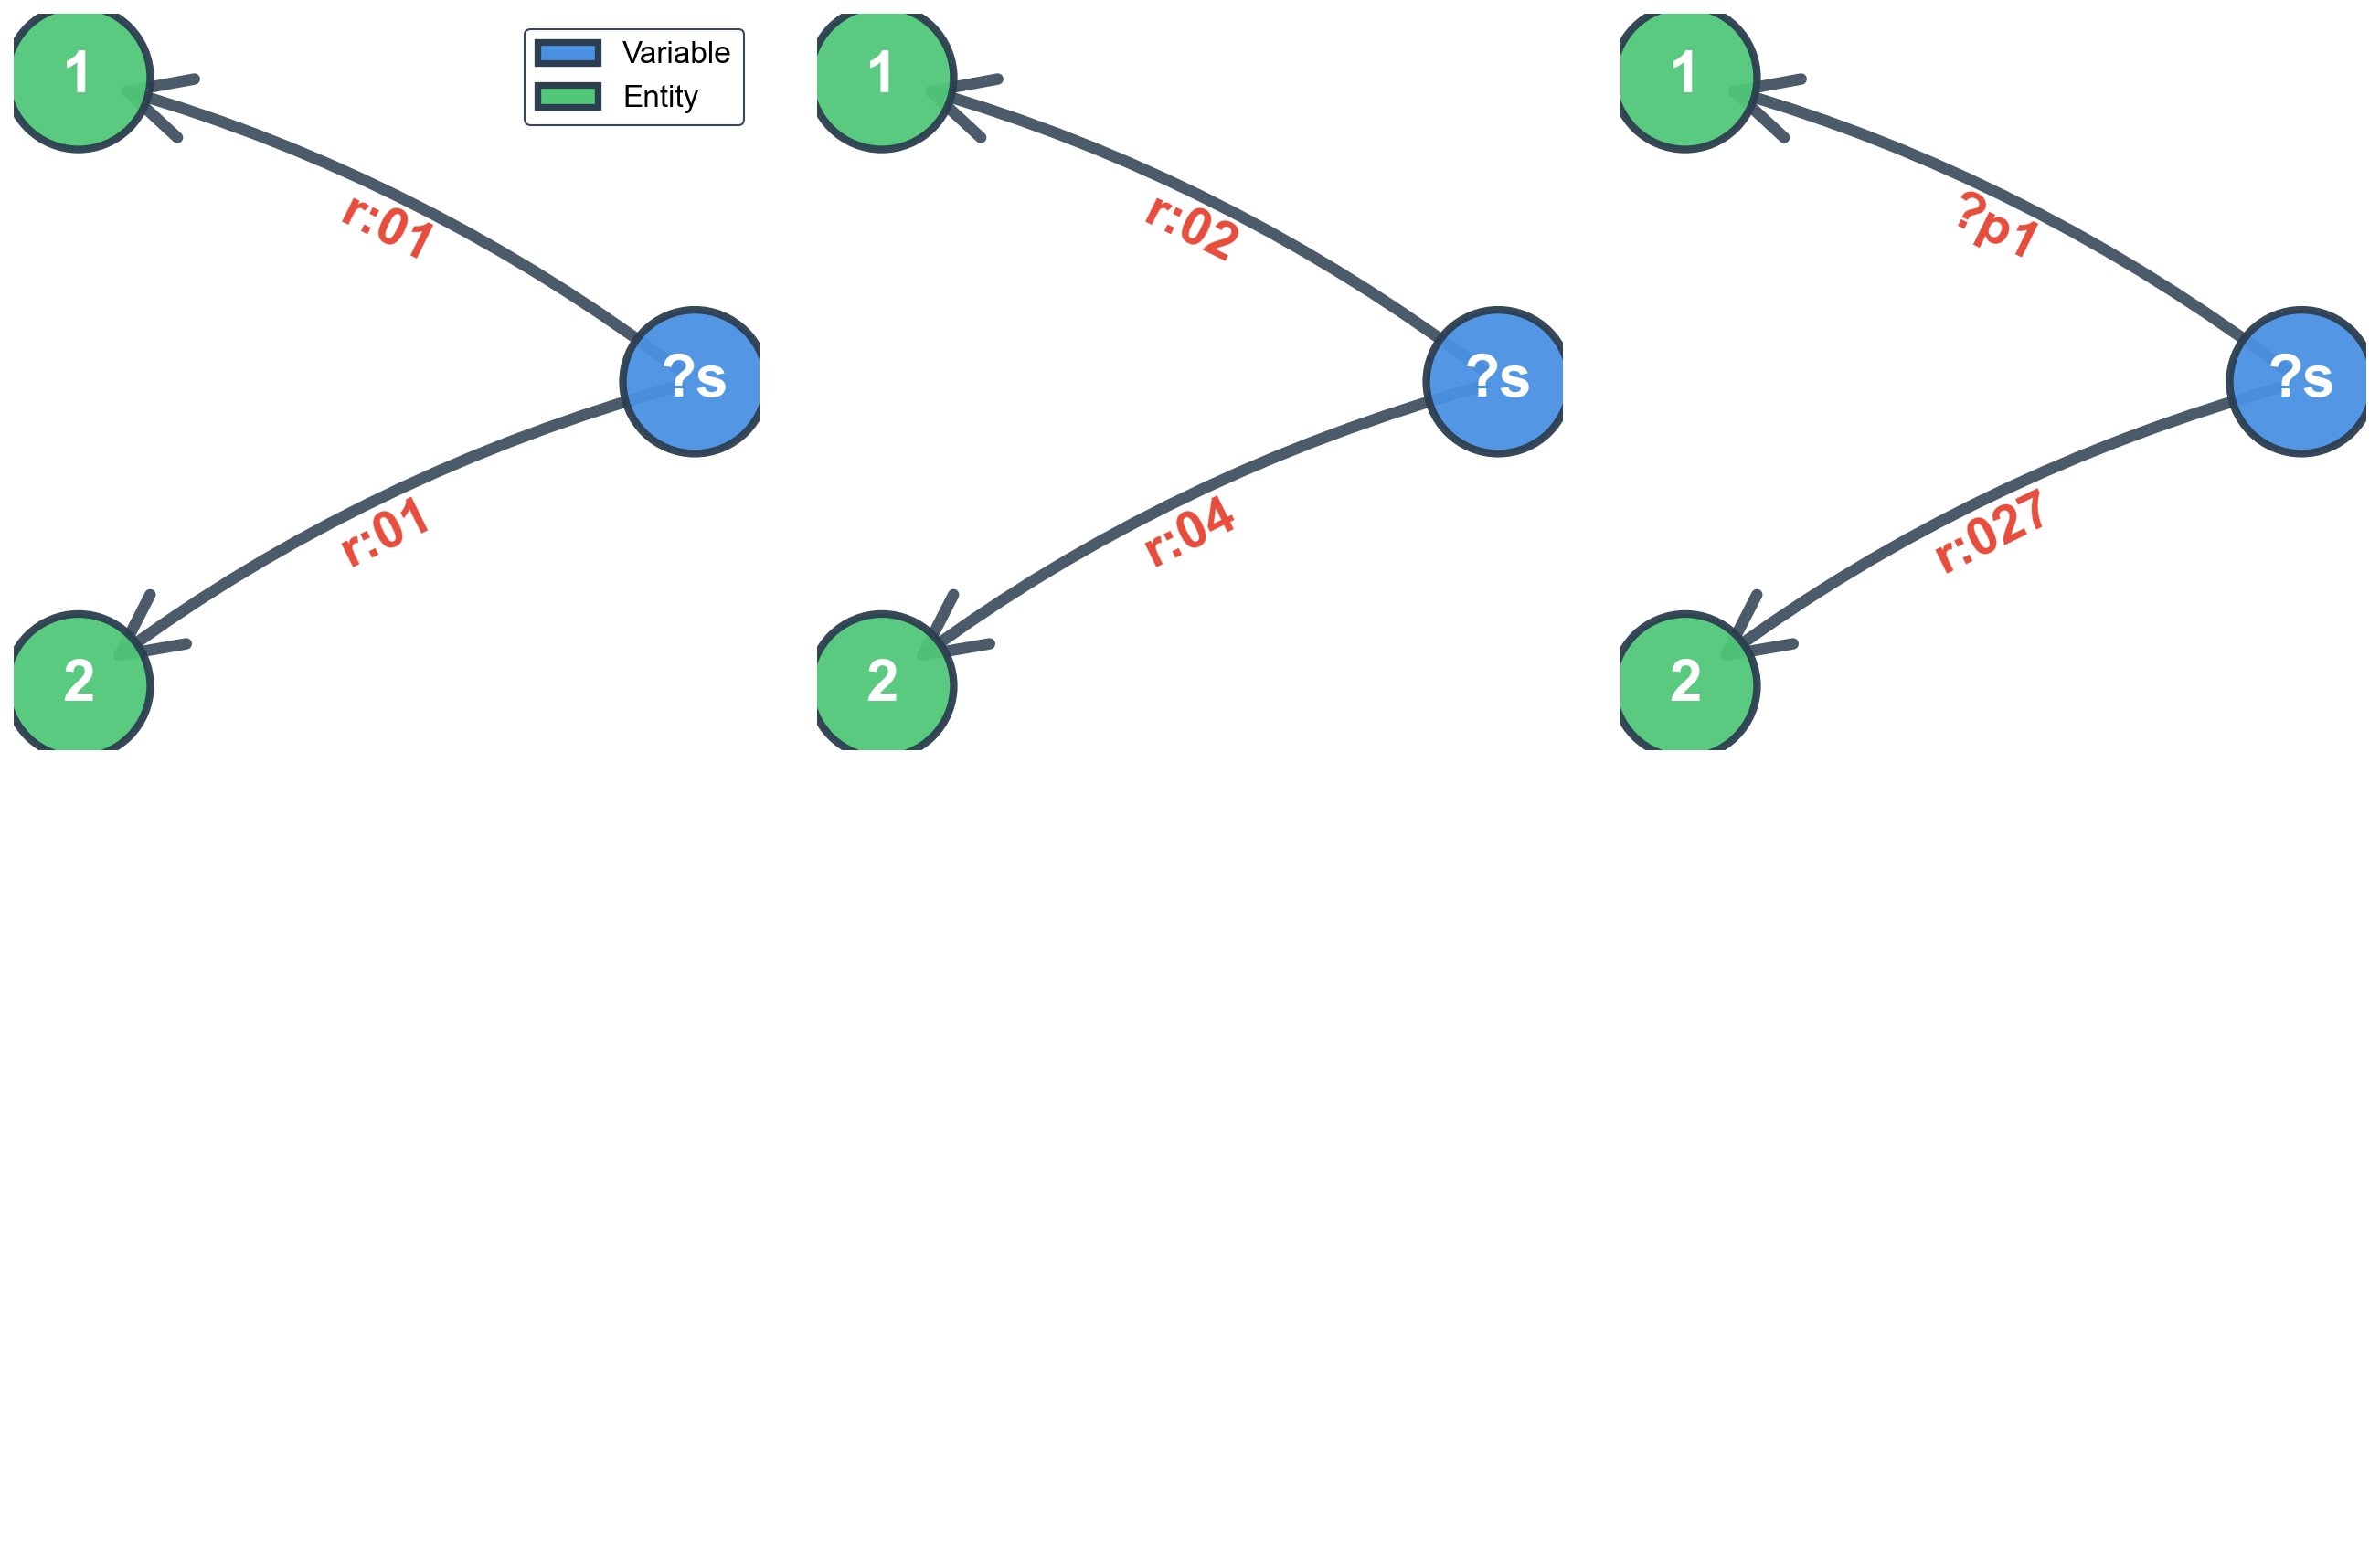

In [32]:
# Separate queries by type
star_queries = [q for q in queries if detect_query_type(q) == 'star']
path_queries = [q for q in queries if detect_query_type(q) == 'path']

print(f"Star queries: {len(star_queries)}")
print(f"Path queries: {len(path_queries)}")

# Create comparison visualization
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Visualize 3 star queries
for i in range(min(3, len(star_queries))):
    if i < len(star_queries):
        visualize_query(star_queries[i], ax=axes[0, i], title_prefix=f"Star #{i+1} | ", show_legend=(i==0))

# Visualize 3 path queries
for i in range(min(3, len(path_queries))):
    if i < len(path_queries):
        visualize_query(path_queries[i], ax=axes[1, i], title_prefix=f"Path #{i+1} | ", show_legend=False)

# Hide any unused axes
for i in range(3):
    if i >= len(star_queries):
        axes[0, i].axis('off')
    if i >= len(path_queries):
        axes[1, i].axis('off')

plt.tight_layout()
plt.show()

## 7. Advanced Usage

### 7.1 Load and Compare Multiple Querysets

Compare queries from different datasets or query types.

In [33]:
# Example: Load path queries and star queries from the same dataset
# Uncomment and modify paths as needed

# path_queries_file = "../data/lubm_path_queries/raw/<filename>"
# star_queries_file = "../data/lubm_queries/raw/<filename>"

# path_queries = load_queryset(path_queries_file, show_stats=False)
# star_queries = load_queryset(star_queries_file, show_stats=False)

# print(f"\\nPath queries: {len(path_queries)}")
# print(f"Star queries: {len(star_queries)}")

# # Visualize samples from each
# fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# if len(path_queries) > 0:
#     visualize_query(random.choice(path_queries), ax=axes[0], title_prefix="Path | ")
# if len(star_queries) > 0:
#     visualize_query(random.choice(star_queries), ax=axes[1], title_prefix="Star | ", show_legend=False)
# plt.show()

print("💡 Uncomment and modify the code above to compare different querysets")

💡 Uncomment and modify the code above to compare different querysets


### 7.2 Export Visualizations

Save visualizations to files for use in papers or presentations.

In [34]:
# Export a single query visualization
# output_dir = Path("../output/query_visualizations")
# output_dir.mkdir(parents=True, exist_ok=True)

# # Visualize and save
# query_to_save = queries[0]
# fig, ax = visualize_query(query_to_save)
# fig.savefig(output_dir / "example_query.png", dpi=300, bbox_inches='tight')
# fig.savefig(output_dir / "example_query.pdf", bbox_inches='tight')  # For LaTeX
# plt.close(fig)

# print(f"Saved visualizations to {output_dir}")

print("💡 Uncomment the code above to export visualizations")

💡 Uncomment the code above to export visualizations


## Summary

This notebook provides a complete toolkit for visualizing query graphs from FICE queryset files:

✅ **Features:**
- Load any queryset JSON file
- Automatic query type detection (star vs path)
- Adaptive layout selection for optimal visualization
- URI simplification for readability
- Statistical analysis and cardinality distribution
- Random sampling and batch visualization
- Filtering by cardinality, triple count, or query type
- Export capabilities for papers/presentations

📝 **Quick Start:**
1. Run the setup cell (Section 1)
2. List available querysets or choose a file path
3. Load queries with `load_queryset(file_path)`
4. Visualize with `visualize_random_queries(queries, n=5)`

🎨 **Customization:**
- Modify `COLOR_VARIABLE` and `COLOR_ENTITY` for different color schemes
- Adjust `figsize_per_plot` in visualization functions
- Change `RANDOM_SEED` for different random samples